In [4]:
import numpy as np
import matplotlib.pyplot as plt
from taia1dvfd.analysis import LotusData, get_model_variable, compute_forecast_score_uv

In [5]:
OUTPUT_FOLDER = "/home/mnex/Desktop/1DV_FD/experiments/2_Lotus_stationary/output"

def _profile_uv(ax, exp_name: str, n_ens: int = 1000, label = None, color = None):
    z_model, t_model, ue_m, ue_v = get_model_variable(f"{OUTPUT_FOLDER}/{exp_name}_ne{n_ens}.nc", "ue", cplx = True)
    
    # 20 days mean, skip the first 10
    idx_t = np.where(t_model/86400 >= 10)[0]
    uem = np.mean(ue_m[idx_t, :], axis = 0)
    uev = np.mean(ue_v[idx_t, :], axis = 0)

    # u-profile
    ax[0].plot(uem.real, z_model, label = label, color = color)
    ax[0].fill_betweenx(z_model, uem.real - uev.real**0.5, uem.real + uev.real**0.5, alpha = 0.1, color = color)

    # v-profile
    ax[1].plot(uem.imag, z_model, label = label, color = color)
    ax[1].fill_betweenx(z_model, uem.imag - uev.imag**0.5, uem.imag + uev.imag**0.5, alpha = 0.1, color = color)

def _eps(exp_name: str, n_ens: int = 1000):
    obs = LotusData()
    ue_obs = obs.u + 1.j*obs.v
    z_model, t_model, ue_m, ue_v = get_model_variable(f"{OUTPUT_FOLDER}/{exp_name}_ne{n_ens}.nc", "ue", cplx = True)
    return compute_forecast_score_uv(ue_m, ue_v, z_model, t_model, n_ens, ue_obs, obs.z, obs.n)

## Testing Li et al. results

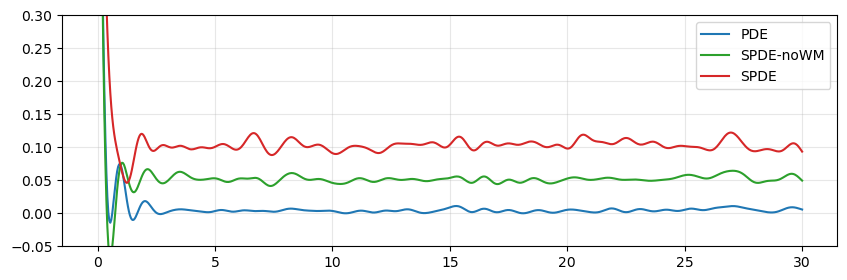

In [6]:
plt.figure(figsize = (10, 3))
plt.plot(*_eps('PDE'),       label = 'PDE',       color = 'C0')
plt.plot(*_eps('SPDE-noWM'), label = 'SPDE-noWM', color = 'C2')
plt.plot(*_eps('SPDE'),      label = 'SPDE',      color = 'C3')
plt.ylim(-0.05, 0.3)
plt.grid(alpha = 0.3)
plt.legend()

In [7]:
# NENS = 1000
# lotus = LotusTools("/home/mnex/Desktop/1DV_FD/experiments/2_Lotus_stationary/output/")

# files_closure_impact = {
#     r'$k-kl$'          : f'k-kl_ne{NENS}.nc',
#     r'$k-\varepsilon$' : f'k-epsilon_ne{NENS}.nc',
#     r'$k-\omega$'      : f'k-omega_ne{NENS}.nc',
#     r'$gen$'           : f'gen_ne{NENS}.nc',
#     r'$TKE$'           : f'tke_ne{NENS}.nc',
#     r'$KPP$'           : f'kpp_ne{NENS}.nc'
#     }

In [8]:
# lotus.plot_mixing(files_closure_impact, figsize=(3, 5), hmax = 100)
# lotus.plot_profiles(files_closure_impact, figsize=(8,4))
# lotus.plot_forecast(files_closure_impact, ne = NENS, ylim = (-0.01, 0.2), figsize=(8,3))